In [2]:
import pandas as pd
import numpy as np

student_df = pd.read_csv('../data/raw/student_mental_health.csv')


In [3]:
print("=== APERÇU ET STRUCTURE GENERALE ===")
print(student_df.head())
print('#' * 80)
student_df.info()
print('#' * 80)
print(f"Dimensions (Lignes, Colonnes) : {student_df.shape}")
print('#' * 80)
print("Types des colonnes :\n", student_df.dtypes)

=== APERÇU ET STRUCTURE GENERALE ===
  Student_ID  Age  Gender  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week  \
0    STU0001   22    Male              3          6.6                  17.6   
1    STU0002   21    Male              4          5.6                  22.4   
2    STU0003   22    Male              5          7.1                  28.1   
3    STU0004   24    Male              1          4.5                  14.8   
4    STU0005   20  Female              1          6.7                  17.2   

    GPA  Social_Media_Hours  Screen_Time_Hours Physical_Activity  \
0  2.91                 6.9                7.5          Moderate   
1  2.92                 7.6               11.5               Low   
2  2.68                 6.5                8.9               Low   
3  2.23                 5.5                7.6              High   
4  2.69                 4.3                7.0          Moderate   

   Financial_Stress  Family_Support  Attendance_Rate Part_Time_Job  \
0        

In [4]:
# 1. Valeurs manquantes (Nombre + Pourcentage)
missing_count = student_df.isna().sum()
missing_pct = (student_df.isna().sum() / len(student_df)) * 100
missing_df = pd.DataFrame({
    'Manquants': missing_count,
    'Pourcentage (%)': missing_pct.round(2)
})
print("\n=== VALEURS MANQUANTES PER COLUMN ===")
print(missing_df[missing_df['Manquants'] > 0].sort_values(by='Manquants', ascending=False))




=== VALEURS MANQUANTES PER COLUMN ===
                    Manquants  Pourcentage (%)
Financial_Stress           91             4.55
Diet_Quality               69             3.45
Sleep_Hours                62             3.10
Social_Media_Hours         58             2.90
Family_Support             54             2.70
Attendance_Rate            47             2.35
GPA                        38             1.90


In [5]:
print("\n=== STATISTIQUES DESCRIPTIVES (NUMERIQUES) ===")
print(student_df.describe(include="number").T)


=== STATISTIQUES DESCRIPTIVES (NUMERIQUES) ===
                       count       mean       std   min     25%    50%    75%  \
Age                   2000.0  21.131500  2.139275  17.0  20.000  21.00  23.00   
Year_of_Study         2000.0   2.630000  1.316802   1.0   1.000   2.00   4.00   
Sleep_Hours           1938.0   6.758875  1.127072   3.3   6.000   6.70   7.60   
Study_Hours_Per_Week  2000.0  19.997900  5.719274   2.4  16.000  19.80  24.00   
GPA                   1962.0   2.562503  0.343993   1.5   2.320   2.56   2.79   
Social_Media_Hours    1942.0   6.013955  1.153422   2.1   5.225   6.00   6.70   
Screen_Time_Hours     2000.0   8.548500  1.657571   3.3   7.400   8.50   9.70   
Financial_Stress      1909.0   5.956260  1.893941   1.4   4.500   6.10   7.40   
Family_Support        1946.0   6.518345  1.844639   1.7   5.100   6.70   8.00   
Attendance_Rate       1953.0  85.080236  7.224118  54.4  80.300  85.10  90.00   

                         max  
Age                    29.00 

In [16]:
# 1. Vérification des limites physiques et logiques
incoherences = {
    'Age < 15 ou > 40': len(student_df[(student_df['Age'] < 15) | (student_df['Age'] > 40)]),
    'Sleep_Hours < 0 ou > 24': len(student_df[(student_df['Sleep_Hours'] < 0) | (student_df['Sleep_Hours'] > 24)]),
    'GPA < 0 ou > 4': len(student_df[(student_df['GPA'] < 0) | (student_df['GPA'] > 4)]),
    'Attendance_Rate < 0 ou > 100': len(student_df[(student_df['Attendance_Rate'] < 0) | (student_df['Attendance_Rate'] > 100)]),
    'Social_Media > Screen_Time': len(student_df[student_df['Social_Media_Hours'] > student_df['Screen_Time_Hours']])
}

# 2. Affichage des résultats
for regle, nb in incoherences.items():
    print(f"{regle} : {nb} anomalie(s)")

# Supprimer les lignes avec incohérence
student_df = student_df[student_df['Social_Media_Hours'] <= student_df['Screen_Time_Hours']]

Age < 15 ou > 40 : 0 anomalie(s)
Sleep_Hours < 0 ou > 24 : 0 anomalie(s)
GPA < 0 ou > 4 : 0 anomalie(s)
Attendance_Rate < 0 ou > 100 : 0 anomalie(s)
Social_Media > Screen_Time : 0 anomalie(s)


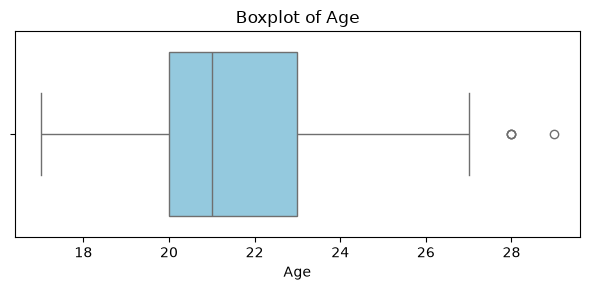

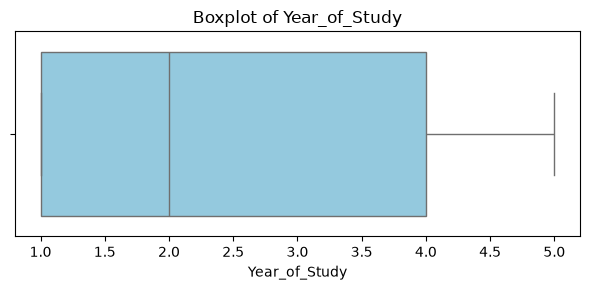

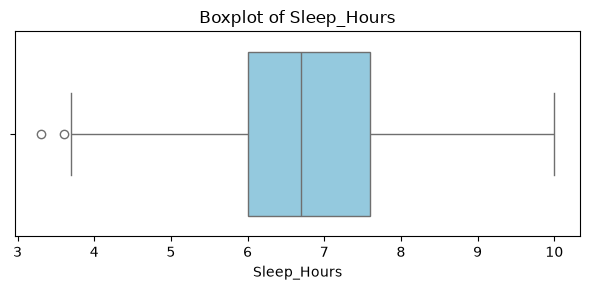

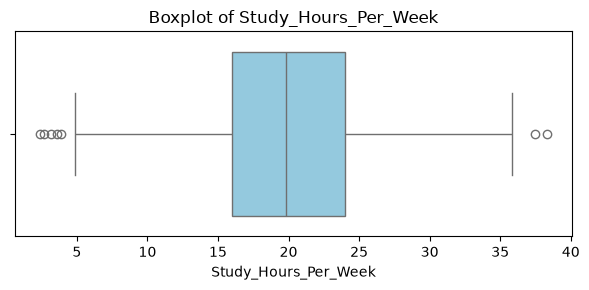

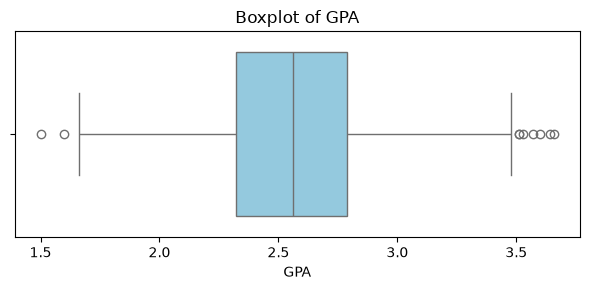

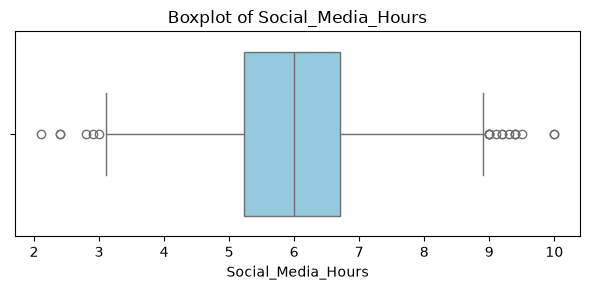

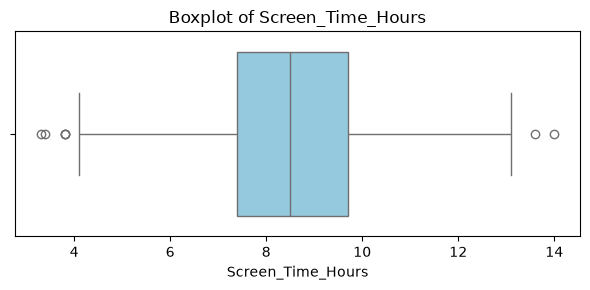

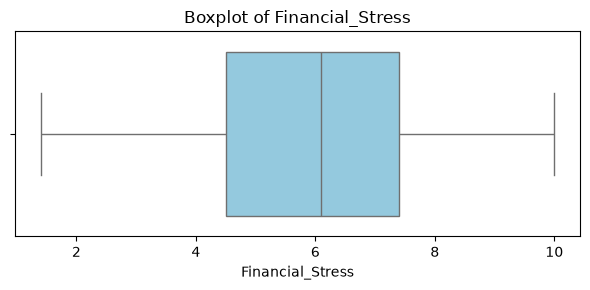

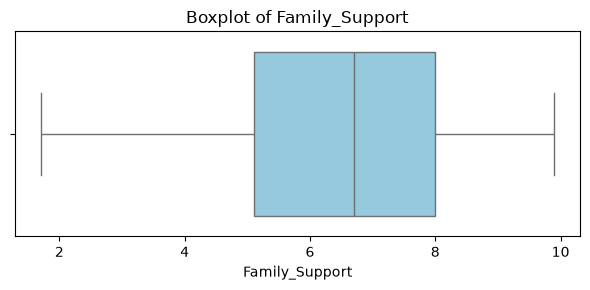

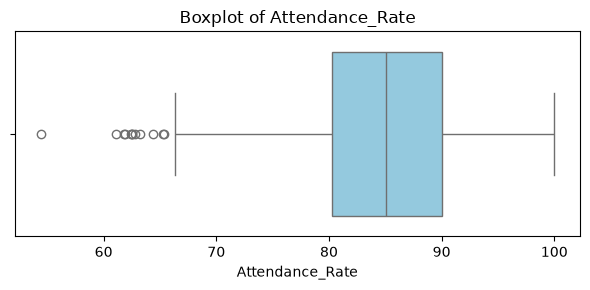

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = student_df.select_dtypes(include="number").columns

for col in num_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=student_df[col], color='skyblue')
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

In [8]:
# 6. Détection et affichage synthétique des outliers par IQR
outliers_summary = []

for col in num_cols:
    Q1 = student_df[col].quantile(0.25)
    Q3 = student_df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = student_df[(student_df[col] < lower_bound) | (student_df[col] > upper_bound)][col]
    
    outliers_summary.append({
        'Variable': col,
        'Borne Inf (Lower)': round(lower_bound, 2),
        'Borne Sup (Upper)': round(upper_bound, 2),
        'Nombre Outliers': len(outliers),
        'Valeurs Extrêmes': sorted(outliers.tolist())
    })

outliers_df = pd.DataFrame(outliers_summary)
print("\n=== RECAPITULATIF DES OUTLIERS (IQR) ===")
print(outliers_df[['Variable', 'Borne Inf (Lower)', 'Borne Sup (Upper)', 'Nombre Outliers']])

print("\n=== VALEURS EXACTES DES OUTLIERS ===")
for item in outliers_summary:
    if item['Nombre Outliers'] > 0:
        print(f"{item['Variable']} ({item['Nombre Outliers']} outliers) : {item['Valeurs Extrêmes']}")



=== RECAPITULATIF DES OUTLIERS (IQR) ===
               Variable  Borne Inf (Lower)  Borne Sup (Upper)  Nombre Outliers
0                   Age              15.50              27.50                4
1         Year_of_Study              -3.50               8.50                0
2           Sleep_Hours               3.60              10.00                2
3  Study_Hours_Per_Week               4.00              36.00                7
4                   GPA               1.61               3.50                9
5    Social_Media_Hours               3.01               8.91               20
6     Screen_Time_Hours               3.95              13.15                7
7      Financial_Stress               0.15              11.75                0
8        Family_Support               0.75              12.35                0
9       Attendance_Rate              65.75             104.55               12

=== VALEURS EXACTES DES OUTLIERS ===
Age (4 outliers) : [28, 28, 28, 29]
Sleep_Hours (2 

In [9]:
num_stats = student_df[num_cols].describe().T
num_stats['median'] = student_df[num_cols].median()

# Réordonner les colonnes pour une meilleure lisibilité
num_stats = num_stats[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max']]

print("=== STATISTIQUES DESCRIPTIVES (VARIABLES NUMÉRIQUES) ===")
print(num_stats)

# -------------------------------------------------------------------------
# B. Statistiques Descriptives Catégorielles (Fréquences & Modes)
# -------------------------------------------------------------------------
cat_cols = student_df.select_dtypes(include=['object']).columns
cat_stats = student_df[cat_cols].describe().T

print("\n=== STATISTIQUES DESCRIPTIVES (VARIABLES CATÉGORIELLES) ===")
print(cat_stats)

=== STATISTIQUES DESCRIPTIVES (VARIABLES NUMÉRIQUES) ===
                       count       mean       std   min     25%  median  \
Age                   2000.0  21.131500  2.139275  17.0  20.000   21.00   
Year_of_Study         2000.0   2.630000  1.316802   1.0   1.000    2.00   
Sleep_Hours           1938.0   6.758875  1.127072   3.3   6.000    6.70   
Study_Hours_Per_Week  2000.0  19.997900  5.719274   2.4  16.000   19.80   
GPA                   1962.0   2.562503  0.343993   1.5   2.320    2.56   
Social_Media_Hours    1942.0   6.013955  1.153422   2.1   5.225    6.00   
Screen_Time_Hours     2000.0   8.548500  1.657571   3.3   7.400    8.50   
Financial_Stress      1909.0   5.956260  1.893941   1.4   4.500    6.10   
Family_Support        1946.0   6.518345  1.844639   1.7   5.100    6.70   
Attendance_Rate       1953.0  85.080236  7.224118  54.4  80.300   85.10   

                        75%     max  
Age                   23.00   29.00  
Year_of_Study          4.00    5.00  
Sle

C:\Users\ycode\AppData\Local\Temp\ipykernel_18044\3367174877.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = student_df.select_dtypes(include=['object']).columns


Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


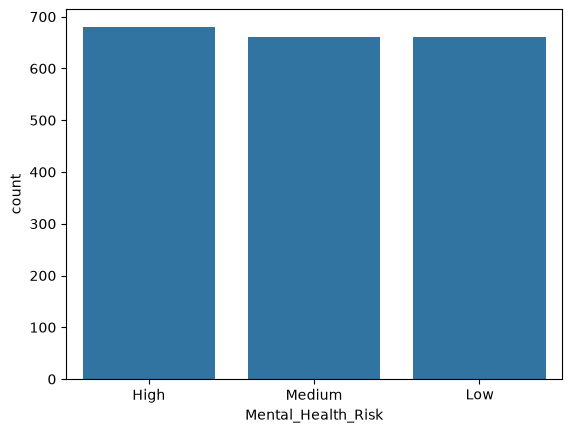

In [10]:
print(student_df['Mental_Health_Risk'].value_counts())

sns.countplot(data=student_df, x='Mental_Health_Risk')
plt.show()

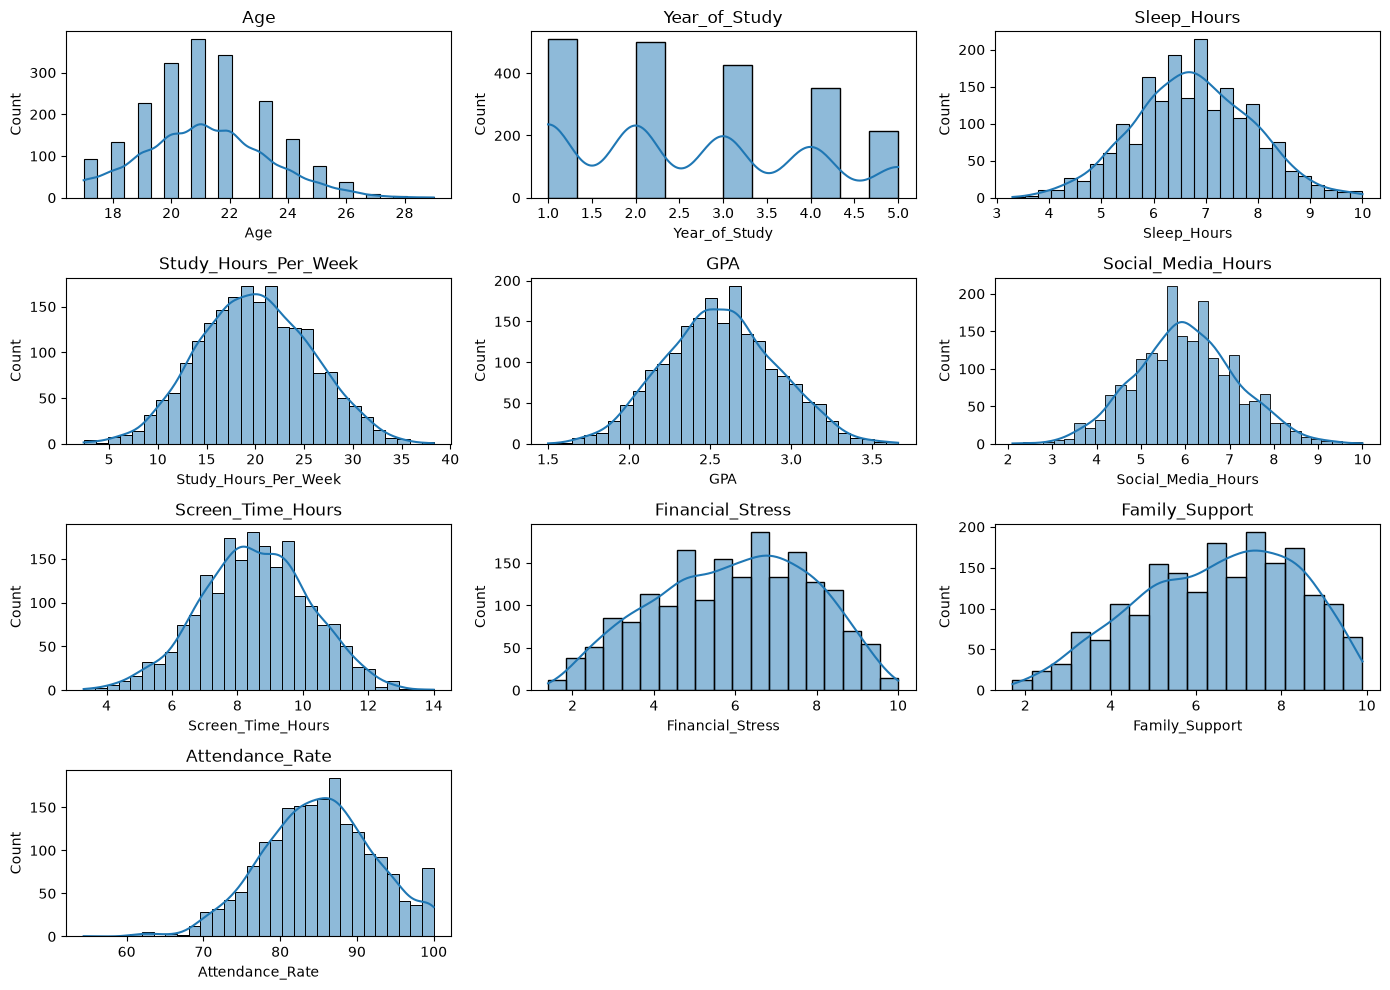

In [11]:
plt.figure(figsize=(14, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(4, 3, i)
    sns.histplot(student_df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

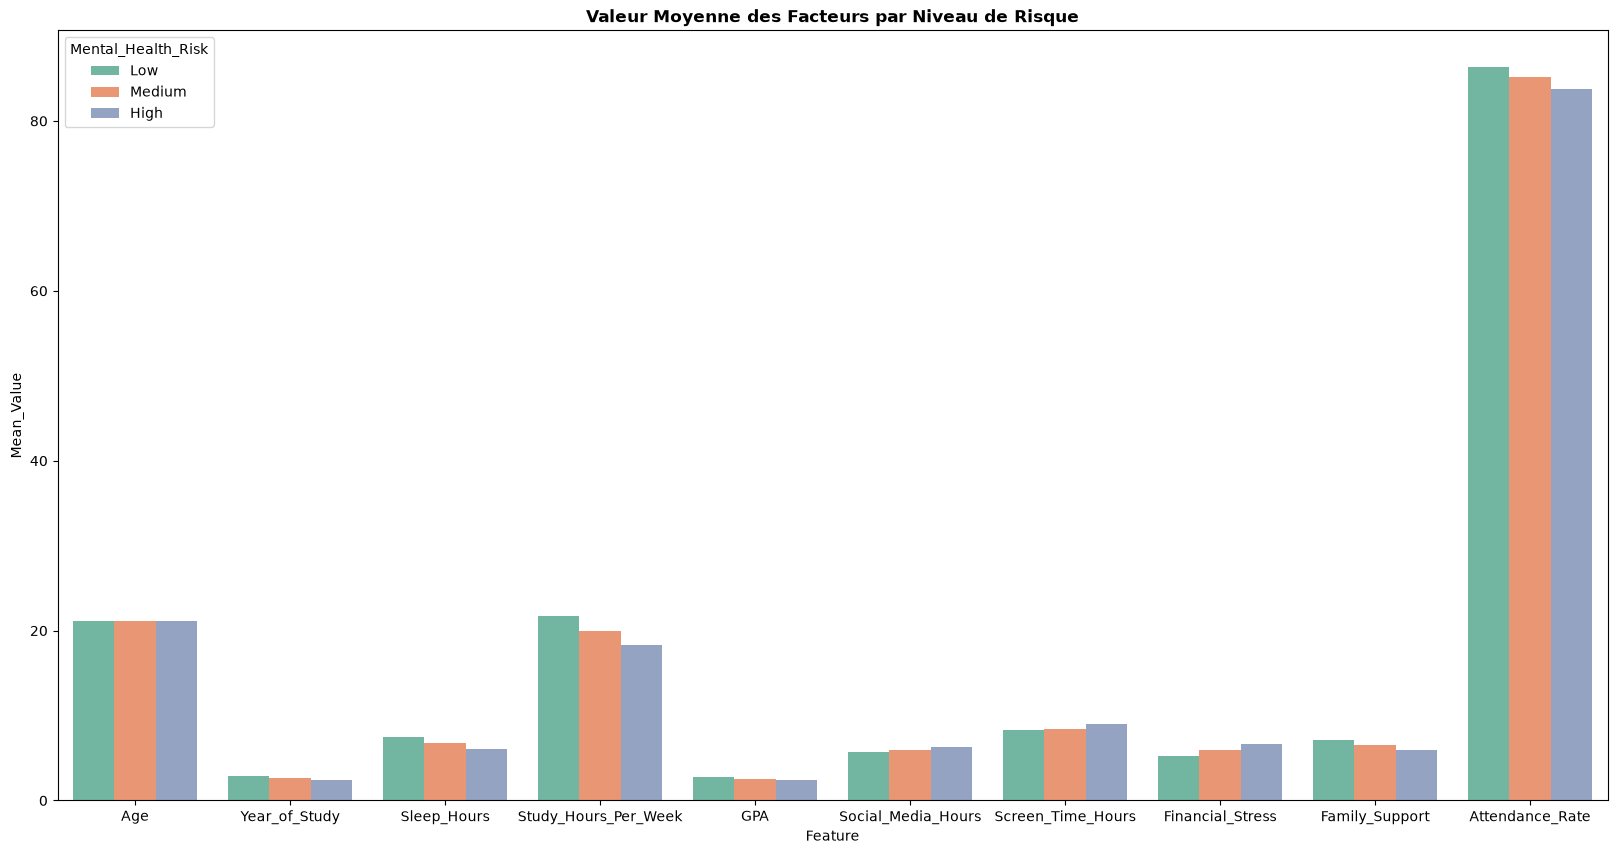

In [12]:
mean_df = student_df.groupby('Mental_Health_Risk')[num_cols].mean().loc[['Low', 'Medium', 'High']].reset_index()
melted_mean = pd.melt(mean_df, id_vars=['Mental_Health_Risk'], var_name='Feature', value_name='Mean_Value')

# Barplot groupé
plt.figure(figsize=(20, 10))
sns.barplot(data=melted_mean, x='Feature', y='Mean_Value', hue='Mental_Health_Risk', palette='Set2')
plt.title('Valeur Moyenne des Facteurs par Niveau de Risque', fontsize=12, fontweight='bold')
plt.show()

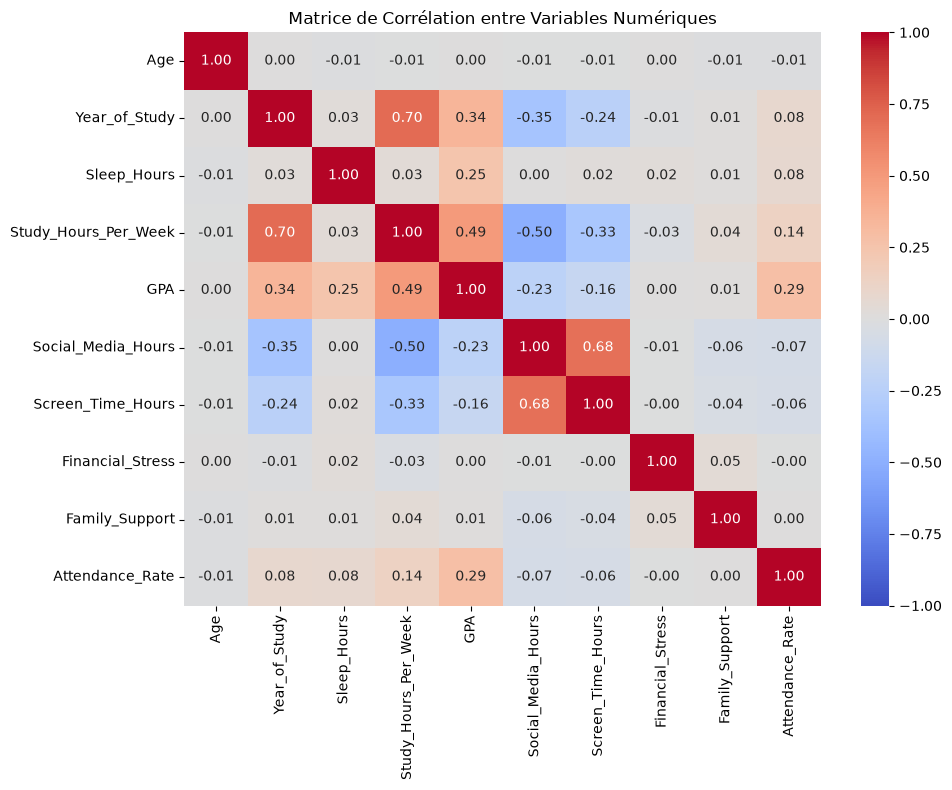

In [13]:
corr = student_df[num_cols].corr()

# 2. Affichage du Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de Corrélation entre Variables Numériques")
plt.tight_layout()
plt.show()

In [14]:
student_df['Risk_Encoded'] = student_df['Mental_Health_Risk'].map({'Low': 0, 'Medium': 1, 'High': 2})

# 2. Corrélation avec le risque
print(student_df.select_dtypes(include='number').corr()['Risk_Encoded'])

Age                     0.004961
Year_of_Study          -0.166404
Sleep_Hours            -0.541857
Study_Hours_Per_Week   -0.238793
GPA                    -0.352626
Social_Media_Hours      0.207601
Screen_Time_Hours       0.173972
Financial_Stress        0.313547
Family_Support         -0.250894
Attendance_Rate        -0.145362
Risk_Encoded            1.000000
Name: Risk_Encoded, dtype: float64
